# Laboratoire de programmation mathématique 5 :<br/> Où sont les nombres premiers ? <span style="color:silver">(théorie analytique des nombres)</span>

Vous savez probablement qu'il existe une infinité de nombres premiers. Pouvons-nous comprendre, au moins approximativement, combien de nombres premiers inférieurs à un $N$ donné existent ? Quelle est la densité des nombres premiers parmi tous les nombres naturels ?

## Trouver les nombres premiers avec le Crible d'Ératosthène

C'est l'un des plus anciens algorithmes (datant supposément du 3ème siècle avant J.-C.). Il trouve tous les nombres premiers $p$ inférieurs à $N$.

- Créer une liste de nombres $2, 3, 4, 5, ..., N-1$
- Commencer avec $p=2$
- Marquer chaque multiple de $p$ dans la liste, sauf $p$ lui-même, comme non-premier (composé)
- Passer au prochain nombre non marqué dans la liste, en faire le nouveau $p$, et répéter

> Le 3ème point peut être optimisé : tous les multiples $k\,p$ où $k<p$ ont déjà été marqués par des nombres premiers plus petits, donc vous pouvez commencer à marquer à partir de $p^2$. _En particulier, une fois que $p>\sqrt{N-1}$, vous pouvez arrêter l'algorithme - aucun autre nombre ne sera marqué de toute façon._

<div style="border: 1px solid gold; padding: 5px">
    
**Exercice :**
 - Implémentez l'algorithme du crible : Écrivez une fonction `sieve(N)` qui renvoie une liste (ou tableau) de longueur `N`, telle que pour chaque $0\leq i <N$, `sieve(N)[i]` est `True` si `i` est un nombre premier et `False` sinon. 
 - Utilisez votre fonction `sieve` pour afficher tous les nombres premiers inférieurs à 1000 (utilisez `print(p, end=' ')` pour économiser de l'espace)
</div>

**Conseils :**
 - Commencez avec la liste `N*[True]` (équivalent à `[True for i in range(N)]`), ou `np.ones(N, dtype=bool)` (qui produit un tableau numpy). Puis changez les valeurs aux indices 0 et 1 à `False` (0 et 1 ne sont pas des nombres premiers), et implémentez l'algorithme du crible (où marquer signifie mettre la valeur à `False`).
 - La syntaxe `for i in range(a, b, c):` signifie que $i$ prendra les valeurs $a$, $a+c$, $a+2c$, $a+3c$,... et la boucle s'arrête quand $i\geq b$ (c'est-à-dire que $a$ est le 'début', $b$ est la 'fin', et $c$ est le 'pas'). Cela pourrait être utile pour votre implémentation. Alternativement, pour les tableaux numpy  (pas pour les listes), vous pouvez utiliser  `arr[a::c] = False` pour mettre les élément `arr[i]` où $i\in a, a+c, a+2c, \dots$ en `False`.


In [23]:
import numpy as np

def sieve(N):
    est_premier = np.ones(N, dtype=bool)

    est_premier[0] = False
    est_premier[1] = False

    p = 2

    while p*p < N:

        if est_premier[p]:
            est_premier[p*p :: p] = False
        p+=1
    return est_premier

N = 1000
nb_premier = sieve(N)

for i in range(N):
    if nb_premier[i]:
        print(i, end= '')

2357111317192329313741434753596167717379838997101103107109113127131137139149151157163167173179181191193197199211223227229233239241251257263269271277281283293307311313317331337347349353359367373379383389397401409419421431433439443449457461463467479487491499503509521523541547557563569571577587593599601607613617619631641643647653659661673677683691701709719727733739743751757761769773787797809811821823827829839853857859863877881883887907911919929937941947953967971977983991997

In [24]:
### EXÉCUTEZ-MOI - TEST 

assert (n := sum(sieve(1000))) == 168, f'il y a 168 nombres premiers inférieurs à 1000, votre algorithme en a trouvé {n}'
print('OK!')

OK!


## Combien de nombres premiers y a-t-il ?

La _fonction de comptage des nombres premiers_ est définie comme :
$$\pi(x) := \text{nombre de nombres premiers qui sont} \leq x.$$
Comment cette fonction se comporte-t-elle, particulièrement pour les grands $x$ ?

Le _théorème des nombres premiers_ affirme que : 
$$\pi(x) \sim \frac x{\log x}$$
(Cette notation signifie que $\displaystyle \lim_{x\to\infty} \frac{\pi(x)}{x/\log x} = 1$). 

Il existe une approximation encore meilleure :
$$\pi(x)\approx \operatorname{Li}(x),$$
où Li ("intégrale logarithmique") est définie comme :
$$\operatorname{Li}(x) := \int_0^x \frac{dt}{\log t}.$$

> Bien que cette fonction puisse sembler compliquée, l'approximation $\pi(x)\approx \operatorname{Li}(x)$ a une jolie signification intuitive : elle nous dit que la densité des nombres premiers près de $n$ (parmi tous les nombres naturels près de $n$) est approximativement $1/\log n$. Autrement dit, "la probabilité qu'un nombre choisi au hasard près de $n$ soit premier est d'environ $1/\log n$".


<div style="border: 1px solid gold; padding: 5px">

**Exercice :**
 - En utilisant votre fonction `sieve`, créez une fonction `prime_counting(N)`. Elle devrait renvoyer la liste des nombres $[\pi(0), \pi(1), \pi(2),\dots, \pi(N-1)]$.
 - Pour $N = 10^6$, tracez (sur la même image) le graphique de $\pi(x)$ (c'est-à-dire la liste `prime_counting(N)`) et les graphiques de $x/\log x$ et de $\operatorname{Li}(x)$, pour $x = 0, 1, 2, \dots, N-1$.
 - Sur l'image suivante (c'est-à-dire après `plt.show()`), tracez les graphiques de $|\pi(x) - x/\log x|$ et de $|\pi(x) - \operatorname{Li}(x)|$. Utilisez l'échelle logarithmique sur les deux axes, car cela donne un meilleur graphique.

</div>

**Conseils :**

 - La façon la plus simple d'implémenter `prime_counting(N)` est avec une boucle for, mais si vous aimez vraiment les astuces python et la compréhension de liste, renseignez-vous sur l'"opérateur morse" (walrus operator). Alternativement, renseignez-vous sur la fonction `np.cumsum`. En tout cas, il faut executer la fonction `sieve` une seule fois, car autrement votre code sera trop lent.
 - Pour obtenir la fonction Li, utilisez
   ```python
   from scipy.special import expi
   ```
   qui importe la fonction "intégrale exponentielle" $$\operatorname{Ei}(x) := \int_{-\infty}^x \frac{e^t}t dt$$ et l'appelle `expi`.
   Utilisez ensuite la formule $\operatorname{Li}(x) = \operatorname{Ei}(\log x)$ (que vous pouvez obtenir par une simple substitution dans l'intégrale).
 - La valeur absolue dans numpy est `np.abs`
 - L'échelle logarithmique sur les deux axes est obtenue par
   ```python
   plt.xscale('log')
   plt.yscale('log')
   ```
> Vous obtiendrez des avertissements, car $x/\log x$ n'est pas défini pour $x =1$. Pour éviter ces avertissements, vous pouvez tracer les fonctions uniquement pour $x\geq 2$. Mais vous devrez être un peu prudent - il pourrait être plus simple d'ignorer les avertissements et de tout tracer pour $x\geq0$ comme suggéré ci-dessus (les "mauvais points" n'apparaîtront pas sur le tracé).

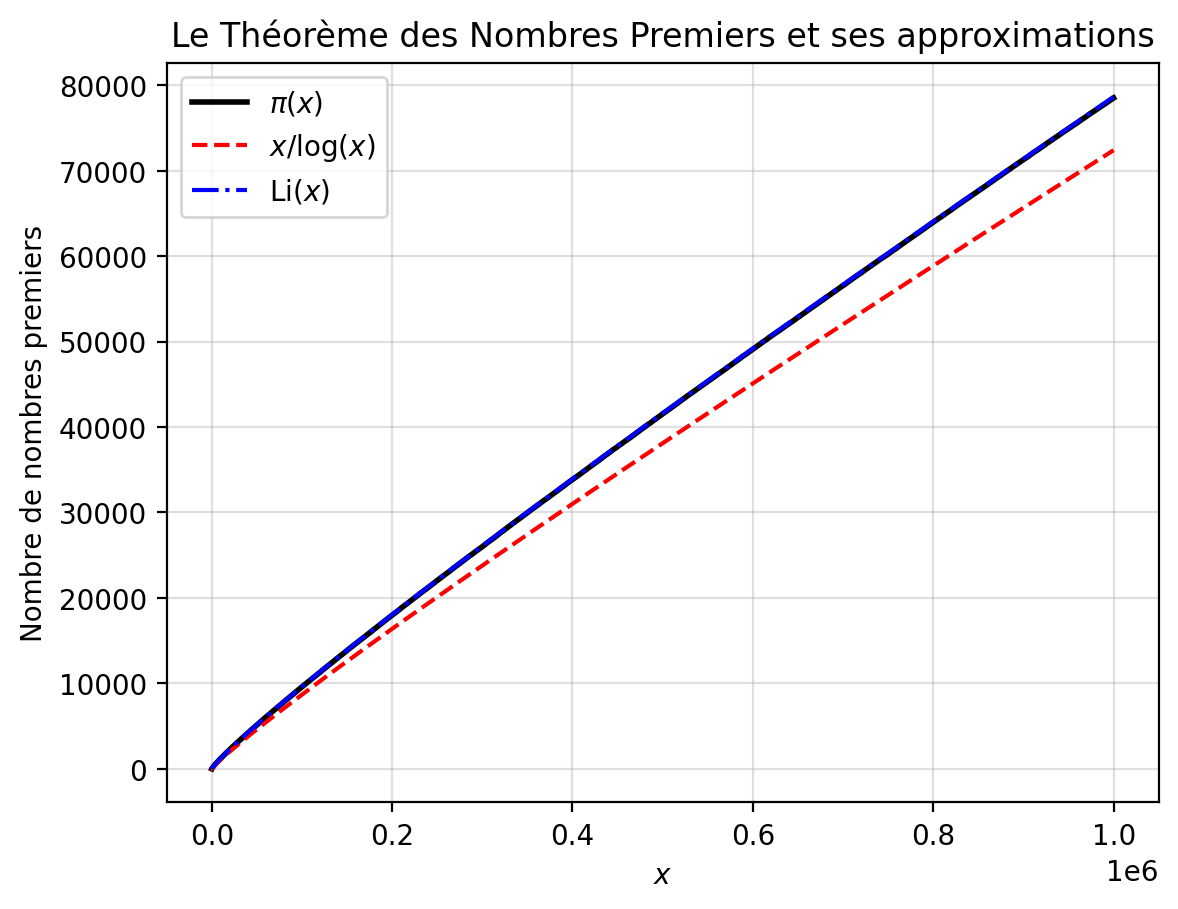

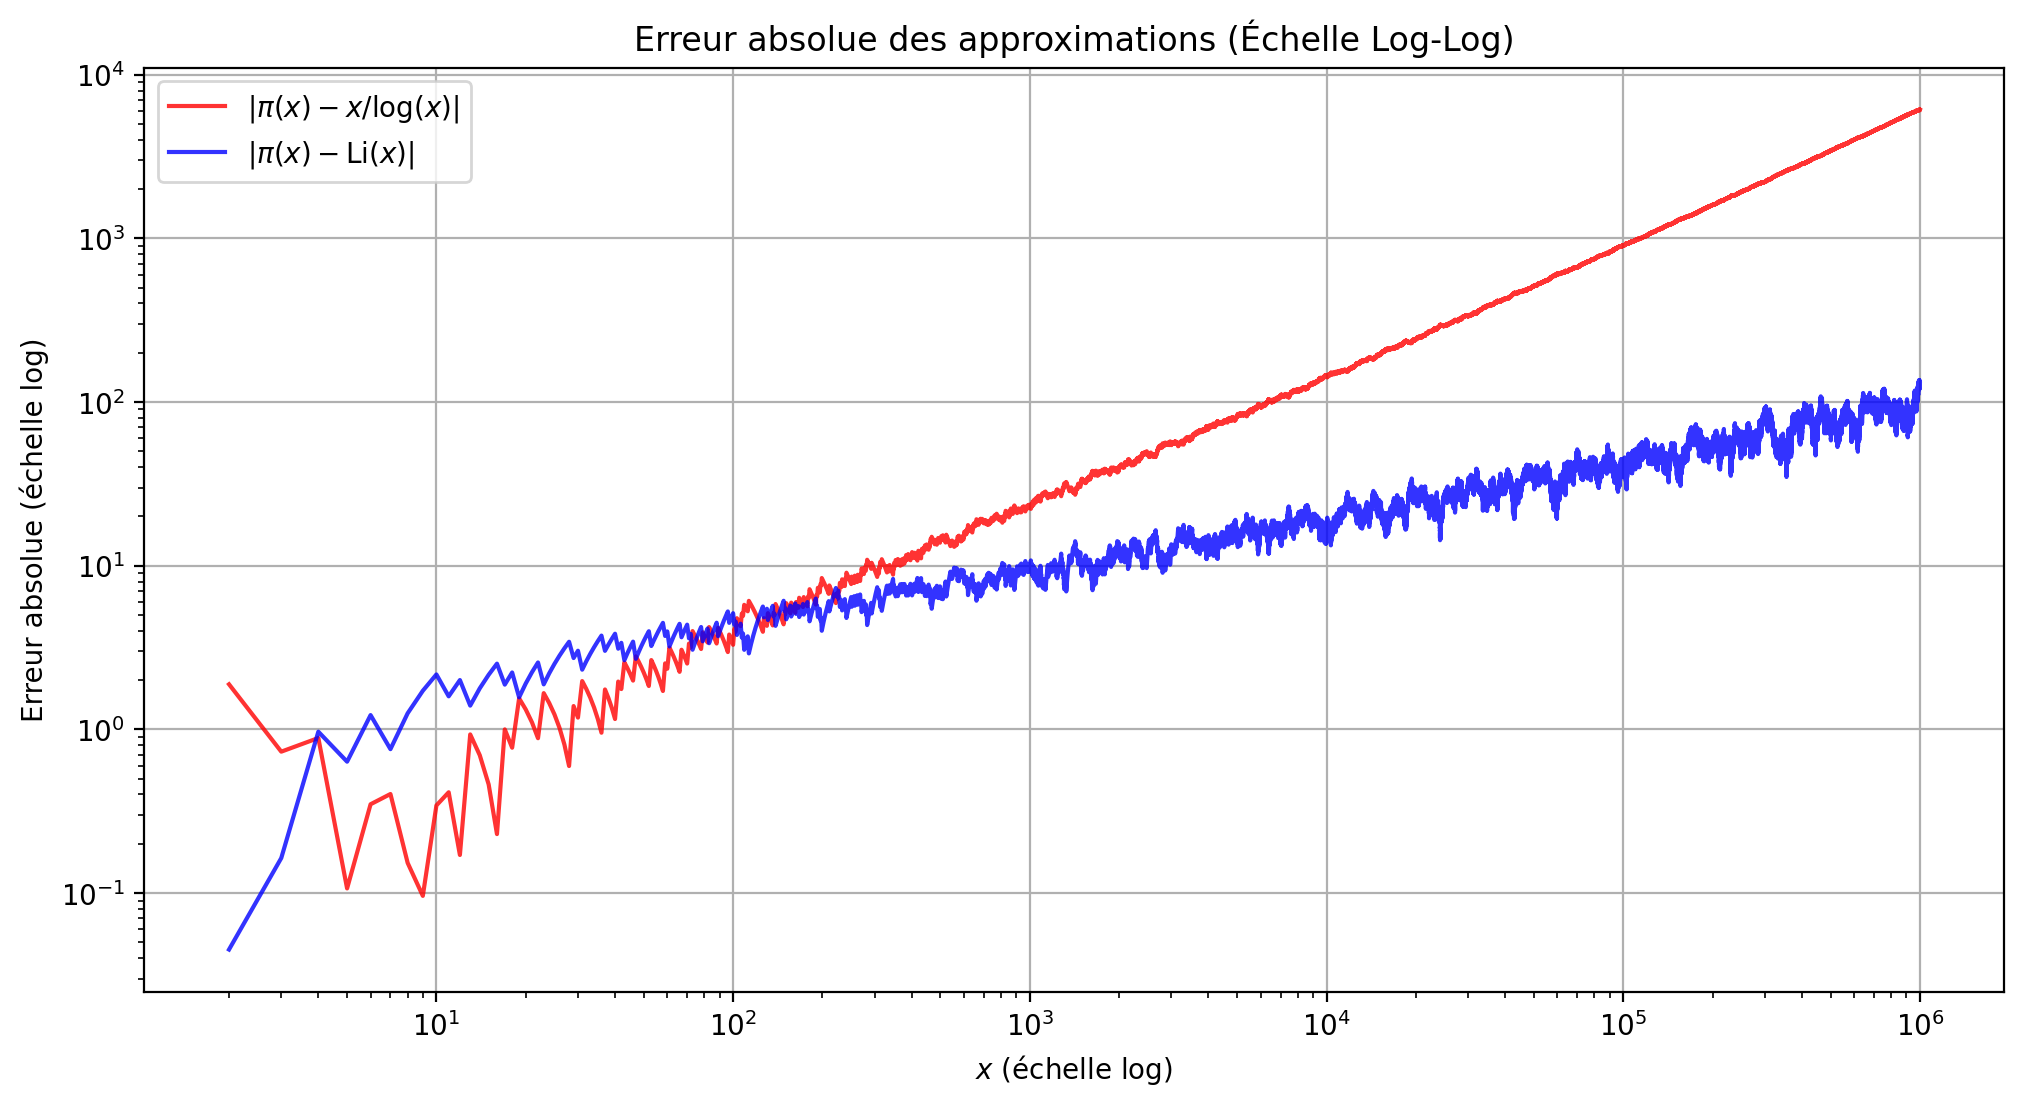

In [25]:
import matplotlib as plt
from scipy.special import expi

%config InlineBackend.figure_format = 'retina'

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expi

%config InlineBackend.figure_format = 'retina'

def prime_counting(N):
    is_prime = sieve(N)
    return np.cumsum(is_prime)

N = 10**6

pi_x_complet = prime_counting(N)

x = np.arange(2, N)
pi_x = pi_x_complet[2:N] 

approx_1 = x / np.log(x)
approx_Li = expi(np.log(x)) 



plt.plot(x, pi_x, label=r'$\pi(x)$', color='black', linewidth=2)
plt.plot(x, approx_1, label=r'$x / \log(x)$', linestyle='--', color='red')
plt.plot(x, approx_Li, label=r'$\mathrm{Li}(x)$', linestyle='-.', color='blue')

plt.title("Le Théorème des Nombres Premiers et ses approximations")
plt.xlabel(r'$x$')
plt.ylabel("Nombre de nombres premiers")
plt.legend()
plt.grid(True, alpha=0.4)
plt.show() 

plt.figure(figsize=(12, 6))

erreur_1 = np.abs(pi_x - approx_1)
erreur_Li = np.abs(pi_x - approx_Li)

plt.plot(x, erreur_1, label=r'$|\pi(x) - x / \log(x)|$', color='red', alpha=0.8)
plt.plot(x, erreur_Li, label=r'$|\pi(x) - \mathrm{Li}(x)|$', color='blue', alpha=0.8)

plt.xscale('log')
plt.yscale('log')

plt.title("Erreur absolue des approximations (Échelle Log-Log)")
plt.xlabel(r'$x$ (échelle log)')
plt.ylabel("Erreur absolue (échelle log)")
plt.legend()
plt.grid()
plt.show()

## Une meilleure façon de compter les nombres premiers

La fonction $\operatorname{Li}(x)$ donne une bonne approximation de $\pi(x)$, mais elle semble un peu effrayante. Cependant, comme nous l'avons déjà mentionné, l'égalité approximative $\pi(x)\approx\operatorname{Li}(x)$ dit simplement que la densité des nombres premiers parmi  les entiers proches de $n$ est approximativement $1/\log n$. Pour se débarrasser de ce $1/\log n$, définissons une nouvelle fonction de comptage des nombres premiers $\theta(x)$, où chaque nombre premier $p$ contribue  $\log p$, et pas seulement  1 comme dans la fonction $\pi(x)$. Nous avons donc
$$\theta(x) = \sum_{p\leq x}\log p$$
où la somme est sur tous les nombres premiers $p$ qui sont $\leq x$.
La fonction $\theta$ est appelée la _première fonction de Chebyshev_ ; bien qu'elle soit différente de $\pi$, elle contient les mêmes informations. L'égalité approximative $\pi(x)\approx\operatorname{Li}(x)$ et équivalente à
$$\theta(x) \approx x.$$
Vérifions-le.


<div style="border: 1px solid gold; padding: 5px">

**Exercice :**

- Écrivez une fonction `chebyshev1(N)` qui renvoie la liste $[\theta(0), \theta(1), \theta(2), \dots, \theta(N-1)]$.
- Pour $N = 10^6$, tracez le graphique de la différence $\theta(x) - x$ sur l'intervalle $[0, N-1]$
- Sur le même intervalle, tracez aussi la différence $\theta(x) - (x - x^{1/2} - x^{1/3})$ 
</div>

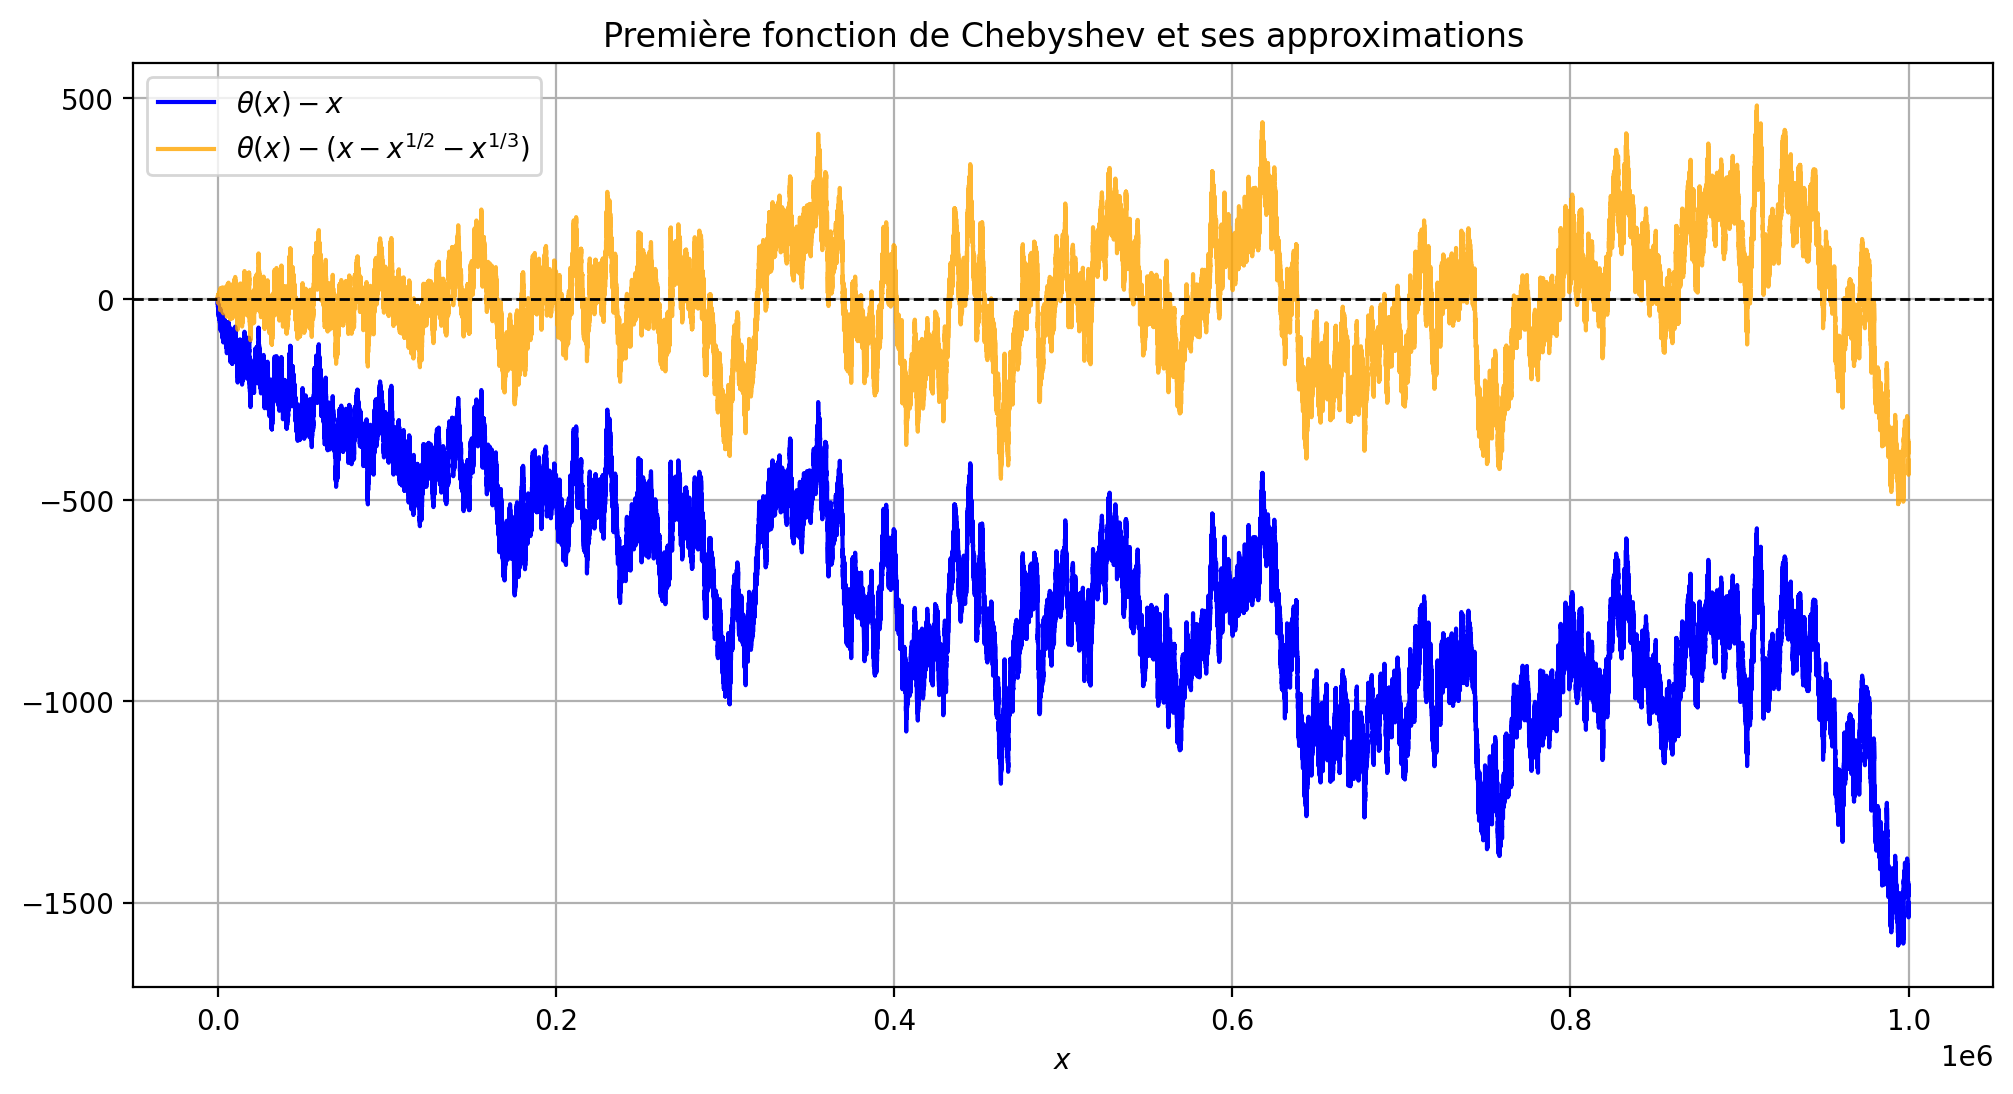

In [26]:
### ÉCRIVEZ ICI

def chebyshev1(N):
    is_prime = sieve(N)
    termes = np.zeros(N)
    indices = np.arange(N)
    
    termes[is_prime] = np.log(indices[is_prime])
    
    return np.cumsum(termes)

N = 10**6
x = np.arange(N)
theta_x = chebyshev1(N)

diff1 = theta_x - x
diff2 = theta_x - (x - x**(1/2) - x**(1/3))

plt.figure(figsize=(12, 6))

plt.plot(x, diff1, label=r'$\theta(x) - x$', color='blue')
plt.plot(x, diff2, label=r'$\theta(x) - (x - x^{1/2} - x^{1/3})$', color='orange', alpha=0.8)

plt.axhline(0, color='black', linestyle='--', linewidth=1)

plt.title("Première fonction de Chebyshev et ses approximations")
plt.xlabel(r'$x$')
plt.legend()
plt.grid()
plt.show()

## Une façon encore meilleure de compter les nombres premiers

Comme nous venons de le voir, $\theta(x)$ s'approche assez bien de $x$, mais la différence $\theta(x) - x$ reste quelque peu mystérieuse : elle oscille et s'éloigne aussi de 0. La différence $\theta(x) - (x - x^{1/2} - x^{1/3})$ semble seulement osciller, mais pour des $x$ très grands, nous verrions encore comment elle dérive  de 0. Que se passe-t-il ? D'où vient l'étrange correction de $x$ en $x - x^{1/2} - x^{1/3}$ et comment devrions-nous la corriger encore davantage ?

Il s'avère qu'il existe une façon encore meilleure de « compter les nombres premiers ». Ceci est donné par la *2e fonction de Tchebychev* $\psi(x)$.
Dans cette fonction, nous comptons non seulement les nombres premiers $p$ mais aussi toutes les puissances de $p$ (tant qu'elles sont $\leq x$) avec le poids $\log p$. C'est-à-dire,
$$\psi(x) = \sum_m \sum_p \log p,$$
où nous sommons sur tous les nombres naturels $m\geq 1$ et sur tous les nombres premiers $p$ tels que $p^m\leq x$.
Nous pouvons aussi exprimer ceci comme :
$$\psi(x) = \sum_{m=1}^\infty \theta(x^{1/m})$$
(Notez que pour tout $x$ spécifique, cette somme contient seulement un nombre fini de termes non nuls, puisque $\theta(x)=0$ quand $x<2$).

> Nous pouvons revenir de $\psi$ à $\theta$, en utilisant la dernière égalité. À savoir,
> $$\theta(x) = \sum_{m=1}^\infty \mu(m)\psi(x^{1/m})$$
> où $\mu$ (la *fonction de Möbius*) est $\mu(m) = (-1)^k$ si $m$ est le produit de $k$ nombres premiers différents, et $\mu(m)=0$ si $m$ est divisible par le carré d'un nombre premier. Voir [formule d'inversion de Möbius](https://en.wikipedia.org/wiki/M%C3%B6bius_inversion_formula).
> Comme nous verrons,
> $$\psi(x)\approx x$$
> _sans aucune dérive_ (seulement avec des oscillations), ce qui nous donne
> $$\theta(x)\approx \sum_{m\geq 1}\mu(m)x^{1/m} = x - x^{1/2} - x^{1/3} - x^{1/5} + x^{1/6} - x^{1/7}+ x^{1/10} -\cdots$$
> expliquant la « correction » de $x$ en $x - x^{1/2} - x^{1/3}$ que nous avons utilisée ci-dessus.


Étonnamment, il existe une formule explicite pour $\psi(x)$ (nous y arriverons bientôt). Pour le moment, nous allons juste vérifier que $\psi(x)\approx x$. En fait, nous allons tracer le graphique de $(\psi(x) - x)/\sqrt x$, car la différence $\psi(x) - x$ est de l'ordre de $\sqrt x$.

<div style="border: 1px solid gold; padding: 5px">

**Exercice :**
- Écrivez une fonction `chebyshev2(N)` qui renvoie la liste $[\psi(0), \psi(1), \psi(2), \dots, \psi(N-1)]$.
- Pour $N=10^4, 10^5, 10^6$ (3 graphiques différents, pour avoir une intuition de ces graphiques), tracez le graphique de la fonction $(\psi(x) - x) / \sqrt x$ dans la plage $10\leq x<N$. Pour rendre les graphiques larges, et pour supprimer la plage peu intéressante $x<10$, utilisez les options
  ```python
  plt.figure(figsize=(15, 3))
  plt.xlim(10, N)
  ```
</div>





> Pourquoi inclure les puissances de nombres premiers dans le comptage, comme nous le faisons dans la définition de $\psi(x)$ ? (Ne lisez pas ceci si ce n'est pas intéressant pour vous.)
>
>  Tout commence par l'observation d'Euler que, pour tout $s > 1$ (c'est-à-dire où les expressions ont un sens), nous avons
> $$\zeta(s):=\sum_{n=1}^\infty \frac1{n^s} = \prod_p\frac1{1-\frac1{p^s}}$$
> où le produit (noté par $\prod$) est sur tous les nombres premiers $p$. C'est simplement parce que
> $$\frac1{1-\frac1{p^s}} = 1 + \frac1{p^s} + \frac1{p^{2s}} + \frac1{p^{3s}} + \cdots$$
> (série géométrique) et parce que chaque $n$ se factorise, de manière unique, en un produit de puissances de nombres premiers.
>
> La fonction $\zeta(s)$ est appelée _fonction $\zeta$ de Riemann_, car Riemann a étendu sa définition à tout $s$ complexe $\neq1$ et a trouvé sa relation avec la distribution des nombres premiers (et beaucoup de ses propriétés étonnantes).
>
> Les sommes sont plus faciles à comprendre que les produits. Pour obtenir une somme au lieu d'un produit sur tous les nombres premiers, nous pouvons appliquer le logarithme à la formule du produit d'Euler. Pour se débarrasser des logarithmes (qui sont un peu laids), nous prenons ensuite la dérivée (pour toute fonction $f$, $(\log f)'=f'/f$, donc le log disparaît) et nous obtenons
> $$-\frac{\zeta'(s)}{\zeta(s)} =  \sum_p \frac{\log p}{p^s}\frac{1}{1-\frac1{p^s}} = \sum_p \sum_{m=1}^\infty\frac{\log p}{(p^m)^s}$$
> Ainsi est apparue la somme sur tous les $p^m$ avec le poids $\log p$. Le passage à la fonction $\psi$ de Tchebychev nécessite encore un peu de travail, mais je m'arrêterai là.



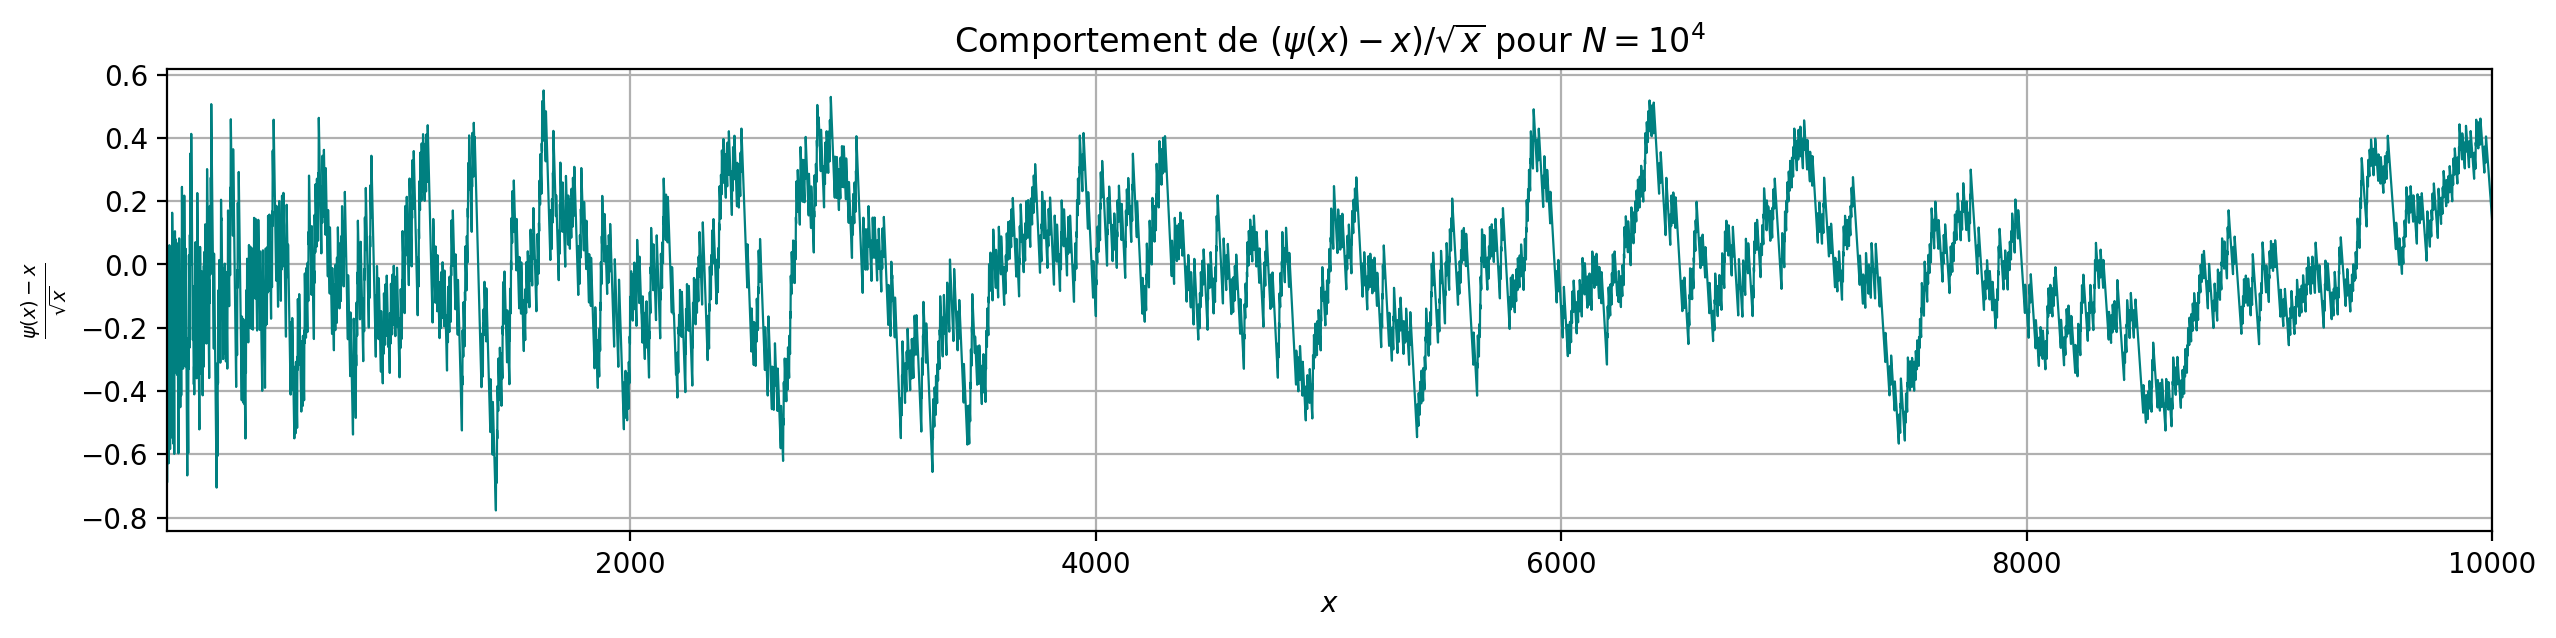

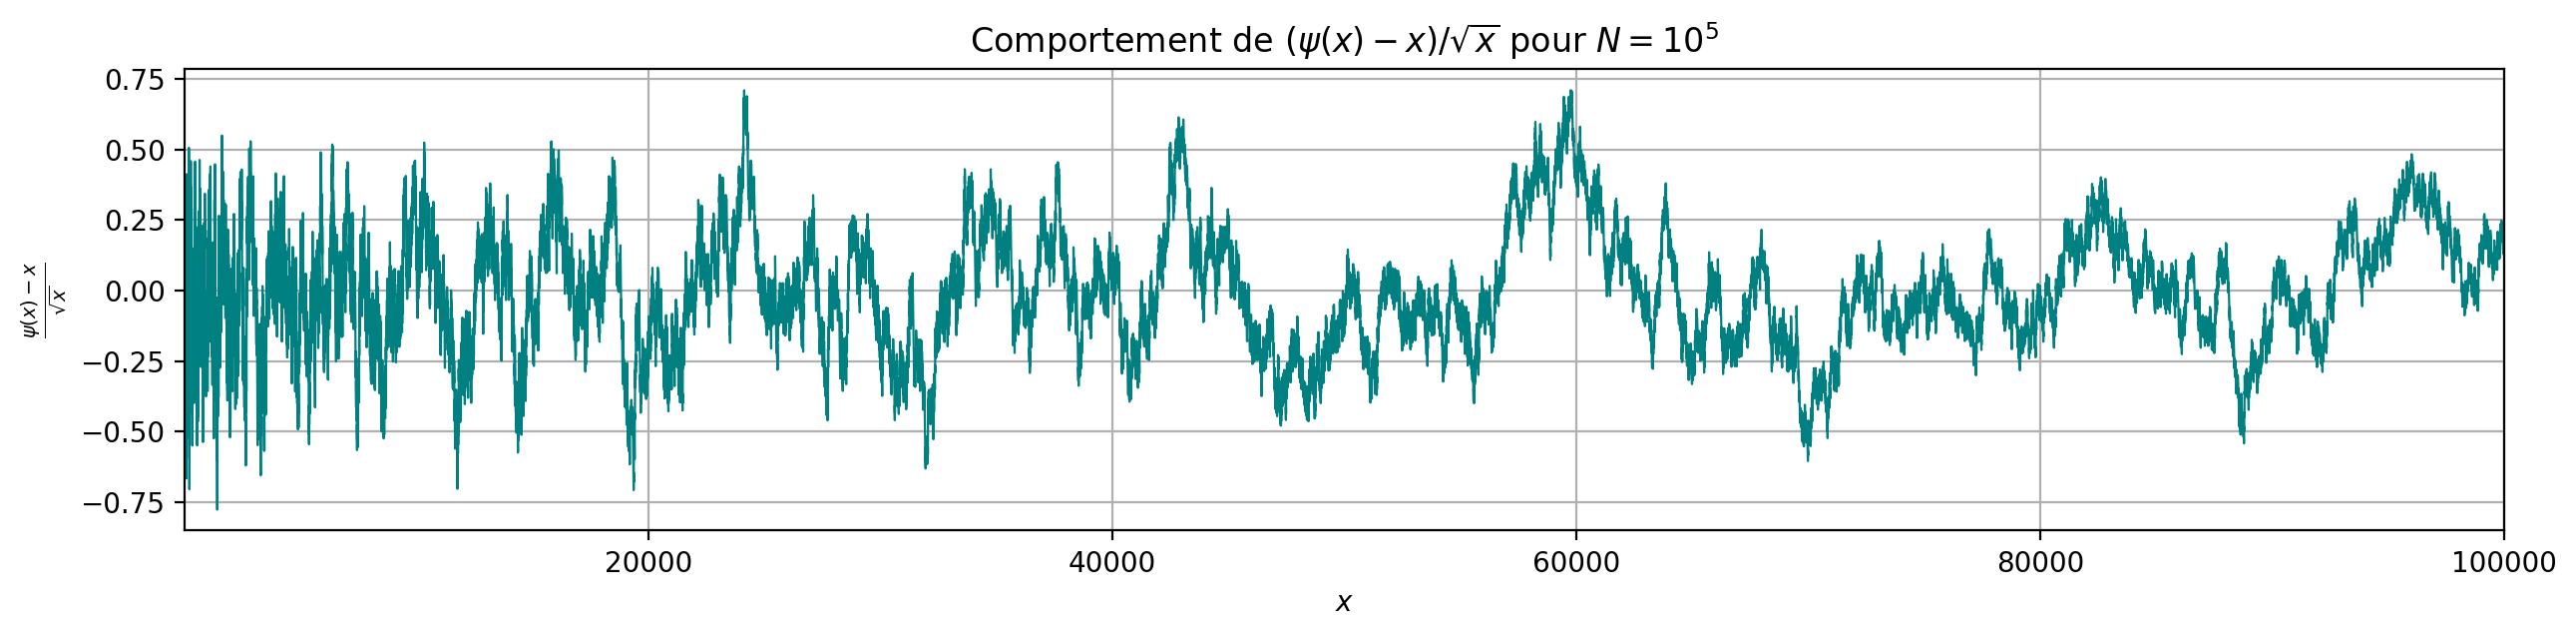

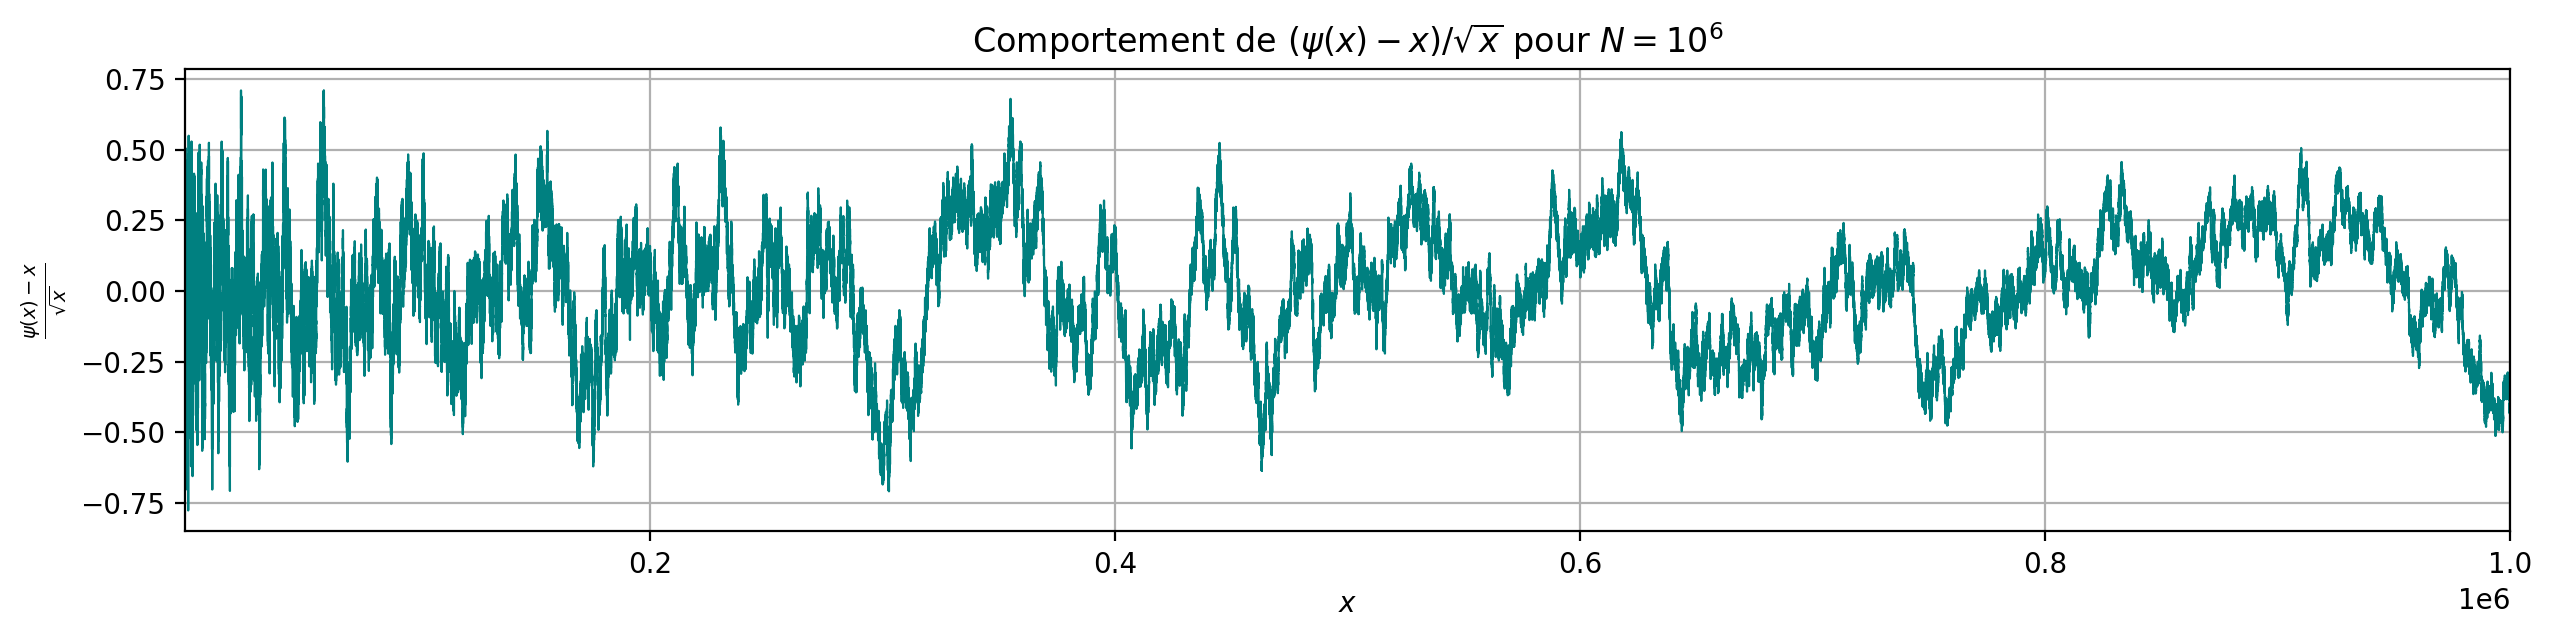

In [27]:

def chebyshev2(N):
    is_prime = sieve(N)
    primes = np.nonzero(is_prime)[0]
    termes = np.zeros(N)
    
    for p in primes:
        puissance = p
        while puissance < N:
            termes[puissance] += np.log(p)
            puissance *= p
            
    return np.cumsum(termes)

valeurs_N = [10**4, 10**5, 10**6]

for N in valeurs_N:
    psi = chebyshev2(N)
    
    x = np.arange(10, N)
    psi_x = psi[10:N]
    
    y = (psi_x - x) / np.sqrt(x)
    
    plt.figure(figsize=(15, 3))
    plt.plot(x, y, color='teal', linewidth=0.8)
    plt.xlim(10, N)
    
    plt.title(fr"Comportement de $(\psi(x) - x) / \sqrt{{x}}$ pour $N = 10^{int(np.log10(N))}$")
    plt.xlabel(r'$x$')
    plt.ylabel(r'$\frac{\psi(x) - x}{\sqrt{x}}$')
    plt.grid()
    
    plt.show()

## "L'harmonie des nombres premiers"

Si tout s'est bien passé, vous devriez voir que $(\psi(x) - x)/\sqrt x$ oscille autour de 0. Là où cette fonction est positive, la densité des nombres premiers et de leurs puissances est légèrement plus élevée, et là où elle est négative, légèrement plus faible. Remarquez comment les longueurs d'onde de ces oscillations augmentent à mesure que $x$ augmente. Si nous utilisions une échelle logarithmique sur l'axe des $x$, les longueurs d'onde apparaîtraient plus cohérentes.

Ces oscillations pointues que nous voyons dans $(\psi(x) - x)/\sqrt x$ ne sont pas un bruit aléatoire - c'est une sorte d'"accord mathématique". Elles peuvent être exprimées comme une somme d'ondes sinusoïdales (dans la variable $\log x$), similaire à la façon dont les accords musicaux peuvent être décomposés en fréquences fondamentales.

Ce qui rend cela vraiment remarquable, c'est que les fréquences sont déterminées par les zéros (racines) de la fonction zêta de Riemann.

> La formule explicite (Riemann - von Mangoldt) pour $\psi(x)$ (pour $x>1$) est
$$\psi(x) = x - \log(2\pi) - \frac12\log(1-x^{-2}) - \sum_\gamma\frac{x^\gamma}\gamma$$
> La somme $\sum_\gamma\frac{x^\gamma}\gamma$ est sur tous les "zéros non triviaux" $\gamma$ de la fonction $\zeta$ de Riemann (elle a aussi des zéros "triviaux" à $-2n$ pour chaque $n\geq1$ - ils contribuent à $-\sum_n\frac{x^{-2n}}{-2n}$, ce qui est exactement le terme $- \frac12\log(1-x^{-2})$). 
>
> L'_Hypothèse de Riemann_ dit que ces racines $\gamma$ (complexes !) de $\zeta$ sont de la forme $\gamma = \frac12 +i\beta$, où $\beta$ sont des nombres réels. C'est probablement le problème ouvert le plus célèbre en mathématiques. Il a été vérifié pour les $10^{13}$ premières racines.
> 
> Si nous réarrangeons la formule et supposons que l'Hypothèse de Riemann est vraie, nous obtenons :
> $$\frac{\psi(x) - x + \log(2\pi) + \frac12\log(1-x^{-2})}{\sqrt x} = -\sum_{\beta >0}\Bigl(\frac{e^{i\beta\log x}}{1/2 + i\beta}+\frac{e^{-i\beta\log x}}{1/2 - i\beta}\Bigr)$$
> (si $1/2 + i\beta$ est une racine de $\zeta$, alors son conjugué complexe $1/2 - i\beta$ l'est aussi)
> ce qui est, grâce à la formule d'Euler $e^{ix} = \cos x + i\sin x$, 
> $$\sum_{\beta>0} c_\beta \sin(\alpha_\beta + \beta\log x)$$
> pour des nombres réels $c_\beta$ et $\alpha_\beta$ appropriés. Ce sont nos ondes sinusoïdales. Les termes supplémentaires à gauche sont petits pour les grands $x$. Let premiers quatre $\beta$ sont
> $$14.1347251417347\quad 21.0220396387716\quad 25.0108575801457\quad 30.4248761258595$$
> 


<div style="border: 1px solid gold; padding: 5px">

**Exercice :**

La fonction `zeta_waves(x, n)` implémentée ci-dessous est la somme des n premières ondes sinusoïdales dérivées des zéros de la fonction zêta de Riemann.

- Tracez $(\psi(x) - x)/\sqrt x$ sur l'intervalle $[100, N=10^5]$ ; vous pouvez réutiliser votre code de l'exercice précédent, mais avec les paramètres ```plt.xlim(100, N)``` (pour restreindre à l'intervalle $[100, N]$) et avec ```plt.xscale('log')``` (le graphique est plus joli en échelle logarithmique)
- Sur le même graphique, ajoutez les tracés de `zeta_waves(x, n)` pour trois valeurs différentes : $n=1$, $n=10$, et $n=30$ 
</div>

**Conseil** : Pour tracer le graphique de `zeta_waves(x, n)` pour disons $n=30$, dans l'intervalle $x\in[100, N]$, utilisez simplement 
```python
plt.plot(x, zeta_waves(x, 30))
```
avec un tableau numpy approprié $x$ couvrant l'intervalle $[100, N]$. Des choix raisonnables sont `x = np.linspace(100, N, N)` ou `x = np.arange(100, N)` (tous les entiers dans l'intervalle $[100, N)$), mais comme nous utilisons l'échelle logarithmique sur l'axe $x$, un meilleur choix est `x = np.geomspace(100, N, 1000)`, qui produit 1000 points qui sont équidistants dans l'échelle logarithmique.


Remarquez comment l'utilisation de $n=30$ fournit une approximation remarquablement bonne de la distribution réelle des nombres premiers, bien qu'elle ne capte pas les oscillations à très courte longueur d'onde. Pour celles-ci, nous aurions besoin d'utiliser un $n$ plus élevé (pour obtenir des ondes sinusoïdales avec des fréquences très élevées).


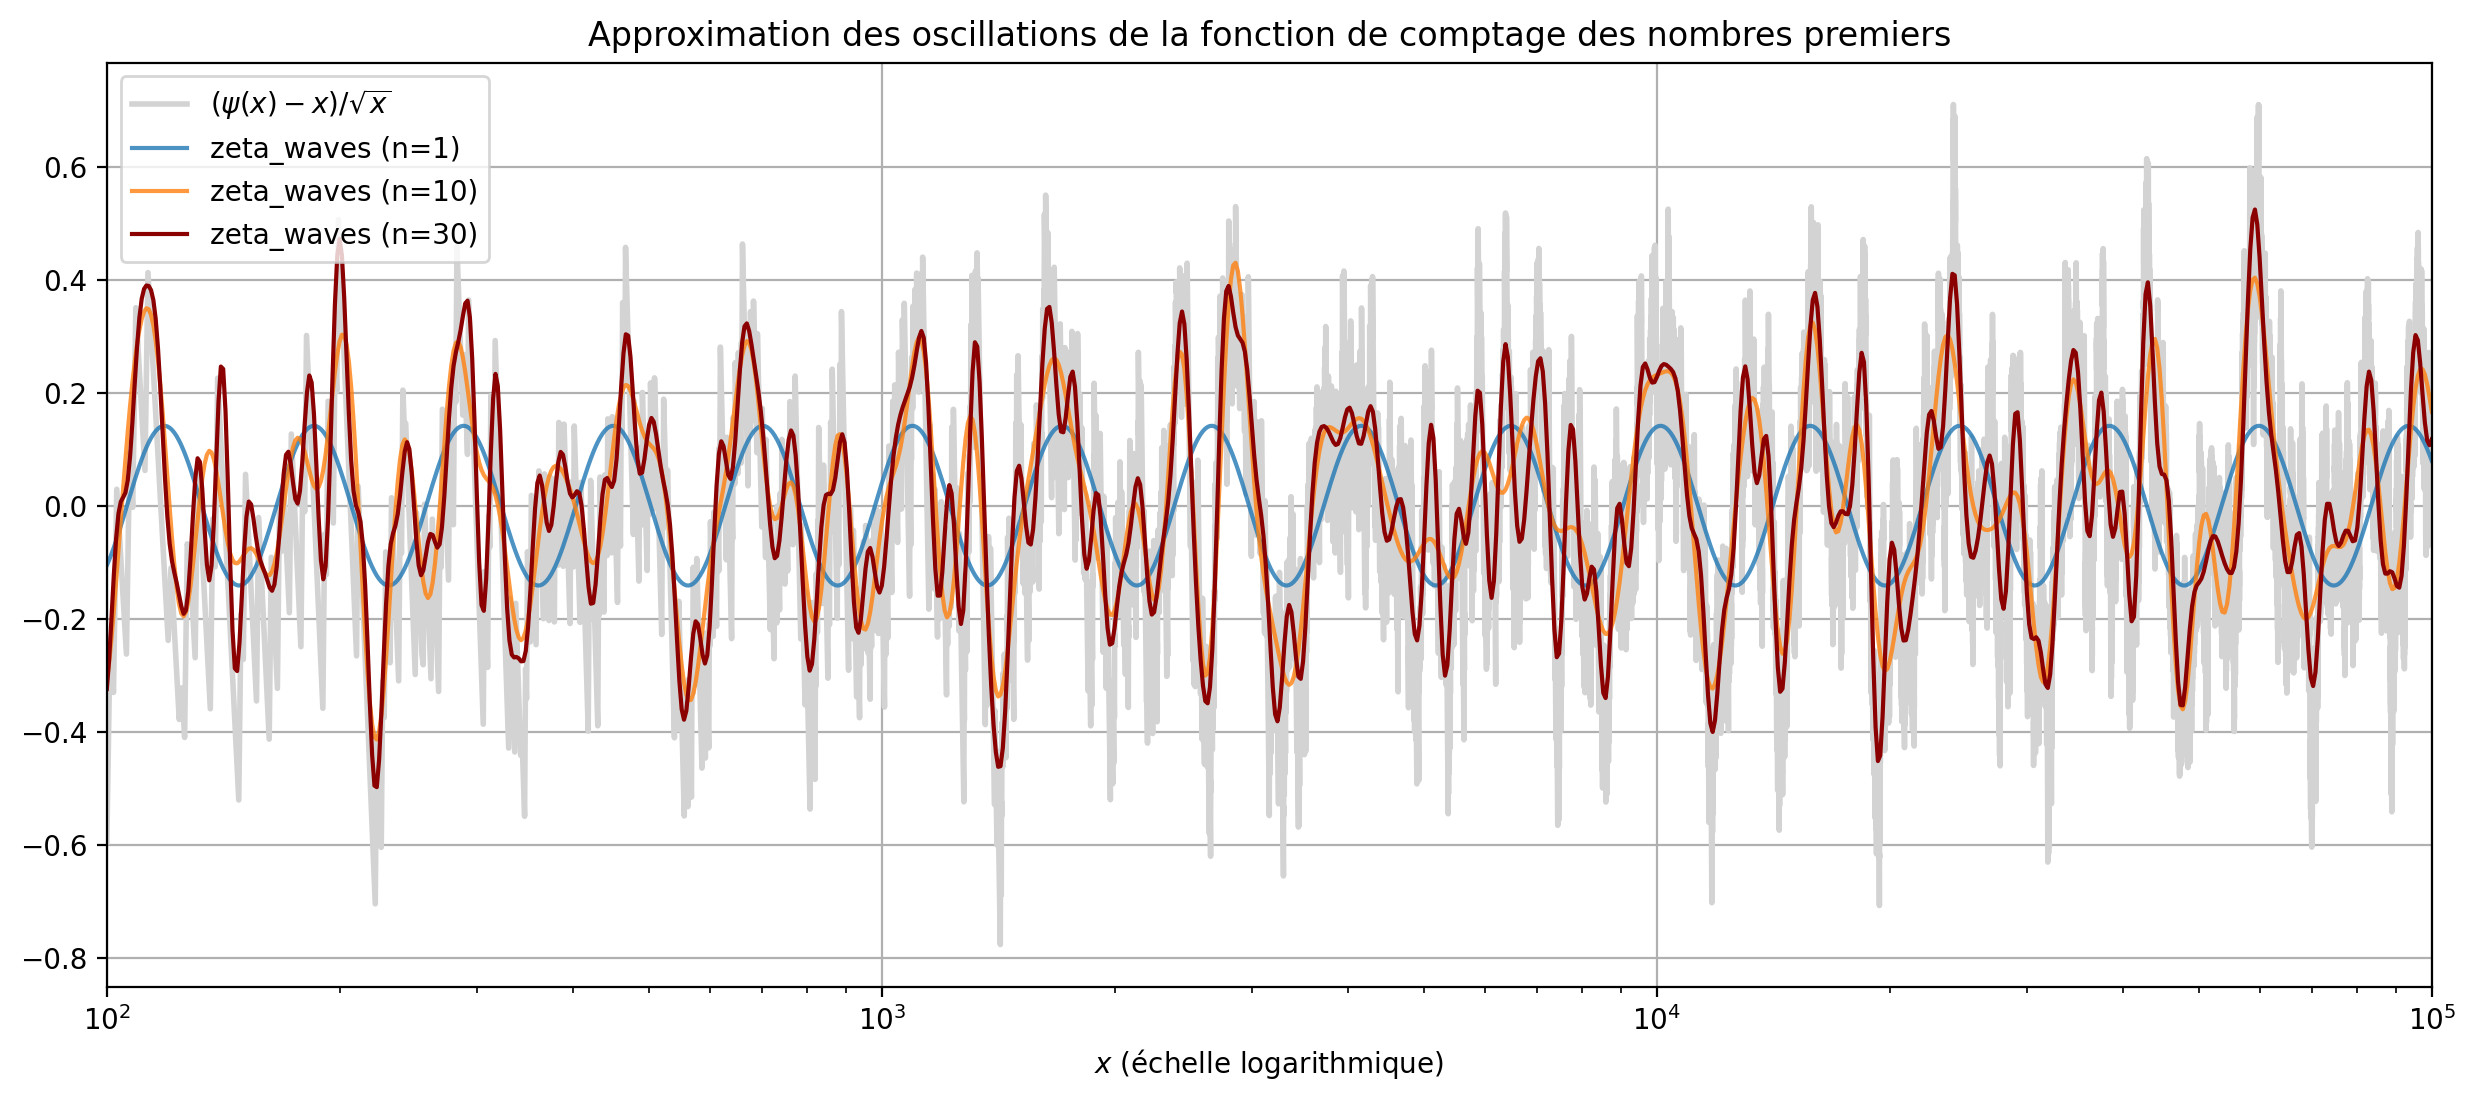

In [28]:
import mpmath  # la bibliothèque numérique de précision arbitraire utilisée par sympy

def zeta_waves(x, n):
    # les n premières racines de zeta avec partie imaginaire positive
    zeta_roots = [complex(mpmath.zetazero(i)) for i in range(1, n+1)]
    # la somme des ondes sinusoïdales
    res = - sum(x**gamma / gamma + x**np.conj(gamma) / np.conj(gamma) for gamma in zeta_roots).real / np.sqrt(x)
    return res

### ÉCRIVEZ ICI

N = 10**5
psi = chebyshev2(N)

x_int = np.arange(100, N)
psi_x = psi[100:N]
y_true = (psi_x - x_int) / np.sqrt(x_int)

x_geom = np.geomspace(100, N, 1000)

y_1 = zeta_waves(x_geom, 1)
y_10 = zeta_waves(x_geom, 10)
y_30 = zeta_waves(x_geom, 30)

plt.figure(figsize=(15, 6))

plt.plot(x_int, y_true, color='lightgray', linewidth=2, label=r'$(\psi(x) - x) / \sqrt{x}$')
plt.plot(x_geom, y_1, alpha=0.8, label='zeta_waves (n=1)')
plt.plot(x_geom, y_10, alpha=0.8, label='zeta_waves (n=10)')
plt.plot(x_geom, y_30, color='darkred', linewidth=1.5, label='zeta_waves (n=30)')

plt.xlim(100, N)
plt.xscale('log')

plt.title("Approximation des oscillations de la fonction de comptage des nombres premiers")
plt.xlabel(r'$x$ (échelle logarithmique)')
plt.legend()
plt.grid()

plt.show()


Enfin, juste pour votre plaisir visuel, voici à quoi ressemble $\zeta(s)$ pour $s$ complexe et où se trouvent ses premières racines. L'image montre $\operatorname{Arg}\zeta(s)$, les points où les couleurs entrent en collision sont les racines de $\zeta$ (et aussi la singularité de $\zeta$, appelée _pôle_, à $s=1$). Exécutez la cellule ci-dessous et profitez-en.


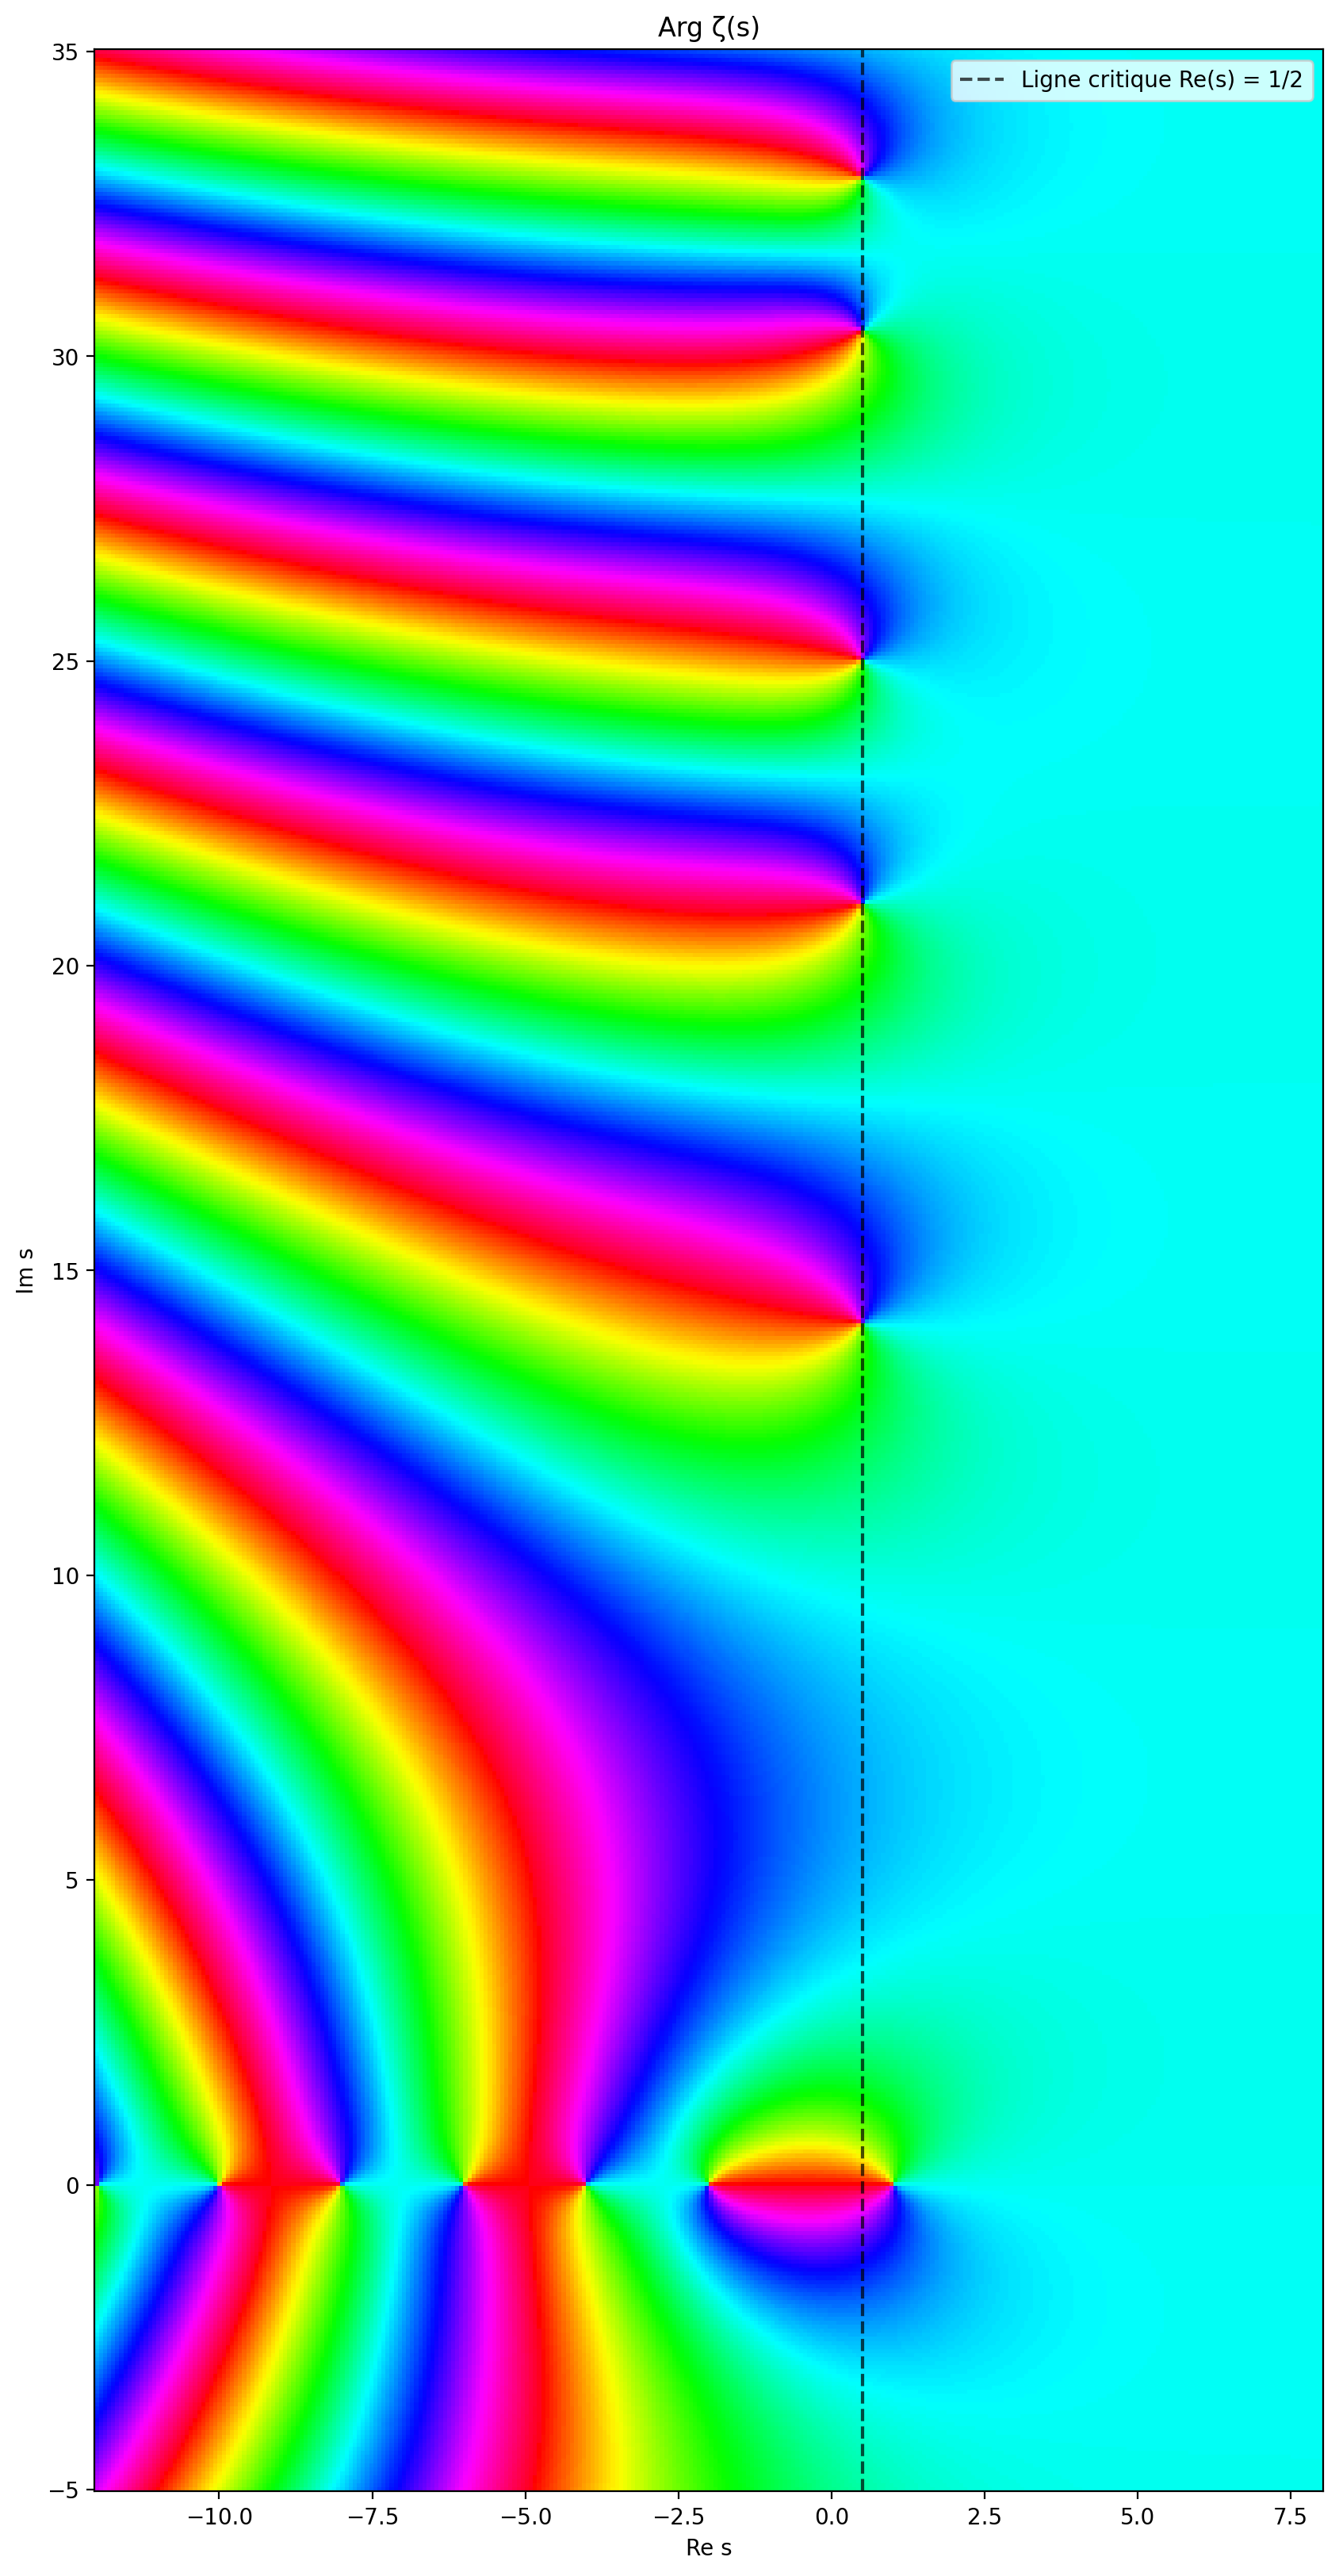

In [29]:
### EXÉCUTEZ-MOI

import scipy
if scipy.__version__ < '1.15.0':
    print('your version od scipy is too old :(')

from scipy.special import zeta

import numpy as np
import matplotlib.pyplot as plt
x = np.linspace(-12, 8, 300)
y = np.linspace(-5, 35, 600)
x, y = np.meshgrid(x, y) 

plt.figure(figsize=(10, 20)) # créer une grande image
plt.axis('equal') # la même échelle pour les axes
plt.pcolormesh(x, y, np.angle(zeta(x + y * 1j)), cmap = 'hsv') # np.angle(z) donne l'argument de z

# Tracer la ligne critique (Re(s) = 1/2)
plt.axvline(x=0.5, color='black', linestyle='--', alpha=0.7, linewidth=1.5, label='Ligne critique Re(s) = 1/2')
plt.legend()
plt.title('Arg ζ(s)')
plt.xlabel('Re s')
plt.ylabel('Im s')
plt.show()